# MM-IMDb — Exploratory Data Analysis

**Scope:** `pranavmr/MM-IMDb`, **only** the Hugging Face `train` split. Implements proposal EDA tasks **1–6 and 12** (genre frequencies, imbalance, labels per movie, text lengths, image sizes, missing/corrupt modalities, and label validation). No cleaning or train/validation/test splitting is performed.

The mirror exposes `image`, `text`, `labels` but **no IMDb movie ID**; entity-level poster–plot identity cannot be audited here. Label checks detect structural anomalies, not whether a genre is semantically correct.

Sources: [dataset](https://huggingface.co/datasets/pranavmr/MM-IMDb) · [official mirror genre vocabulary](https://huggingface.co/datasets/pranavmr/MM-IMDb/blob/main/unique_genres.json) · [proposal](PROPOSAL.md).

## Install, load and inspect

In [4]:
from collections import Counter
from io import BytesIO
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from datasets import load_dataset, Image as HFImage
from transformers import AutoTokenizer
from tqdm.auto import tqdm

# Disable automatic PIL decoding so a corrupt image cannot break loading.
ds = load_dataset("pranavmr/MM-IMDb", split="train").cast_column("image", HFImage(decode=False))
data = pd.DataFrame({"text": list(ds["text"]), "labels": list(ds["labels"])})
print(f"Rows: {len(data):,} | Columns: {ds.column_names}")

# Independent expected label vocabulary from the mirror's unique_genres.json.
GENRES = "Action Adventure Animation Biography Comedy Crime Documentary Drama Family Fantasy Film-Noir History Horror Music Musical Mystery Romance Sci-Fi Short Sport Thriller War Western".split()
assert len(GENRES) == 23

Rows: 25,959 | Columns: ['image', 'text', 'labels']


## Genre frequency and class imbalance
A movie can belong to multiple genres, so percentages **do not** sum to 100%. Counts use each genre at most once per movie.

,movies,percent,imbalance_ratio
Drama,13967,53.80,1.00
Comedy,8592,33.10,1.63
Romance,5364,20.66,2.60
Thriller,5192,20.00,2.69
Crime,3838,14.78,3.64
Action,3550,13.68,3.93
Adventure,2710,10.44,5.15
Horror,2703,10.41,5.17
Documentary,2082,8.02,6.71
Mystery,2057,7.92,6.79


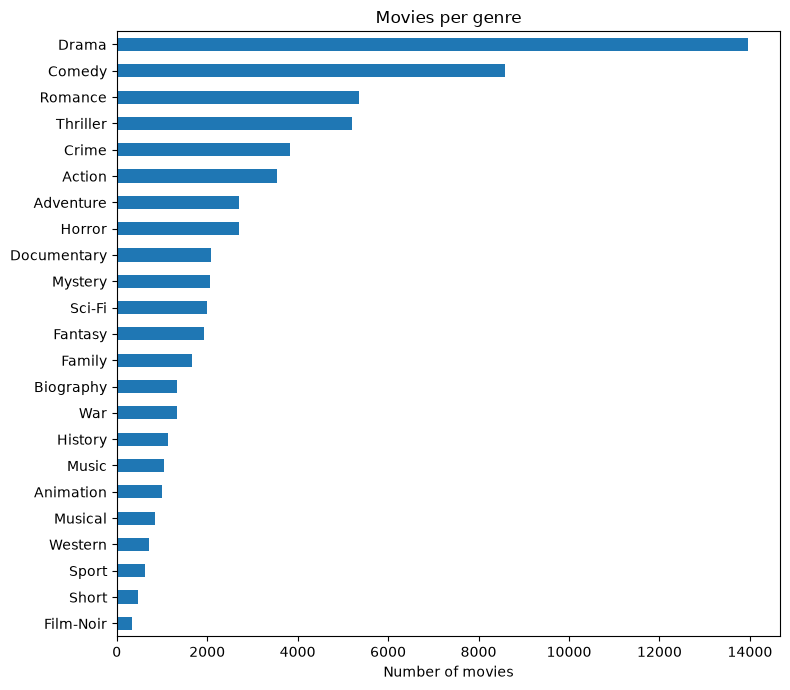

In [5]:
counts = pd.Series(Counter(g for labels in data["labels"] if isinstance(labels, list)
                           for g in set(labels) if g in GENRES)).reindex(GENRES, fill_value=0).sort_values(ascending=False)
genre_summary = pd.DataFrame({"movies": counts, "percent": 100 * counts / len(data),
                              "imbalance_ratio": counts.max() / counts.replace(0, float("nan"))})
display(genre_summary.round(2))
counts.sort_values().plot.barh(figsize=(8, 7), title="Movies per genre")
plt.xlabel("Number of movies"); plt.tight_layout(); plt.show()

## Number of genres per movie (label cardinality)

,genres per movie
count,25959.000000
mean,2.484649
std,1.188583
min,1.000000
25%,2.000000
50%,2.000000
75%,3.000000
max,10.000000


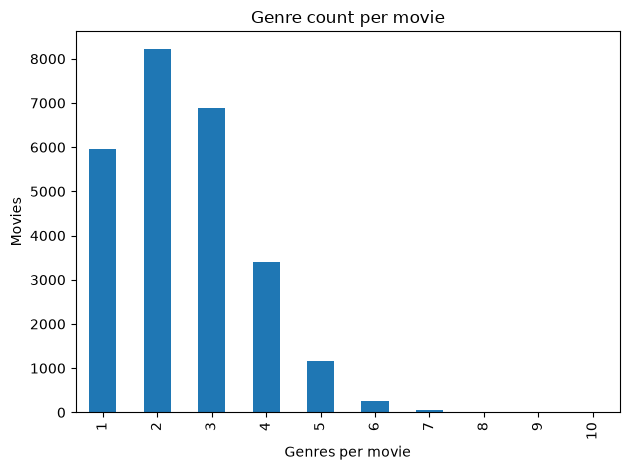

In [6]:
data["n_genres"] = data["labels"].map(lambda x: len(set(x)) if isinstance(x, list) else 0)
display(data["n_genres"].describe().to_frame("genres per movie"))
data["n_genres"].value_counts().sort_index().plot.bar(title="Genre count per movie")
plt.xlabel("Genres per movie"); plt.ylabel("Movies"); plt.tight_layout(); plt.show()

## Text length
Word length uses whitespace separation. Token length uses the **planned DistilBERT tokenizer**, including special tokens and **without truncation**, to measure how often the proposed `max_length=256` would truncate.

Tokenizing plots: 100%|██████████| 51/51 [00:02<00:00, 19.30it/s]


,count,mean,std,min,50%,90%,95%,99%,max
words,25959.0,106.2,77.8,1.0,91.0,206.0,259.0,363.4,1696.0
tokens,25959.0,135.3,97.0,3.0,116.0,260.0,323.0,453.0,1999.0


Plots longer than 256 tokens: 2,667 (10.3%)


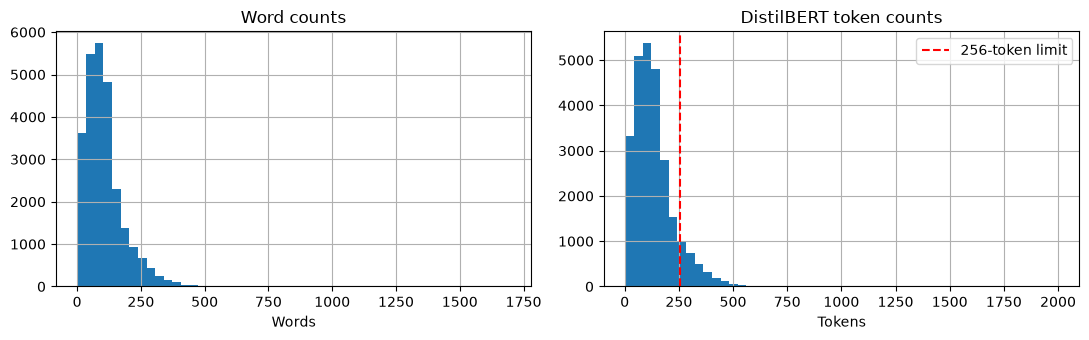

In [7]:
texts = data["text"].map(lambda x: x if isinstance(x, str) else "")
data["words"] = texts.str.split().str.len()
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased", use_fast=True)
lengths = []
for i in tqdm(range(0, len(texts), 512), desc="Tokenizing plots"):
    batch = tokenizer(texts.iloc[i:i+512].tolist(), add_special_tokens=True, truncation=False)["input_ids"]
    lengths.extend(map(len, batch))
data["tokens"] = lengths
display(data[["words", "tokens"]].describe(percentiles=[.5, .9, .95, .99]).T.round(1))
print(f"Plots longer than 256 tokens: {(data['tokens'] > 256).sum():,} ({(data['tokens'] > 256).mean():.1%})")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
data["words"].hist(bins=50, ax=axes[0]); axes[0].set_title("Word counts"); axes[0].set_xlabel("Words")
data["tokens"].hist(bins=50, ax=axes[1]); axes[1].axvline(256, color="red", linestyle="--", label="256-token limit")
axes[1].set_title("DistilBERT token counts"); axes[1].set_xlabel("Tokens"); axes[1].legend()
plt.tight_layout(); plt.show()

## Image dimensions and image–text validity
Decode each image once with Pillow to find missing/corrupt images and collect its native stored dimensions. This is an integrity scan of the **whole train split**; it may take some time. It does not check semantic pairing (IMDb IDs are absent).

In [8]:
image_info = []
for row in tqdm(ds, total=len(ds), desc="Checking images"):
    raw = row["image"]
    if not raw or (raw.get("bytes") is None and not raw.get("path")):
        image_info.append((None, None, None, "missing"))
        continue
    try:
        source = BytesIO(raw["bytes"]) if raw.get("bytes") is not None else raw["path"]
        with PILImage.open(source) as image:
            image.load()
            image_info.append((*image.size, image.mode, "valid"))
    except Exception:
        image_info.append((None, None, None, "corrupt"))

data[["width", "height", "mode", "image_status"]] = pd.DataFrame(image_info, index=data.index)
valid = data["image_status"].eq("valid")
dims = data.loc[valid, ["width", "height"]].copy()
dims["aspect_ratio"] = dims["width"] / dims["height"]

print("Image modes:")
display(data["mode"].value_counts(dropna=False).to_frame("movies"))

resolution_counts = dims.groupby(["width", "height"]).size().sort_values(ascending=False)

if len(resolution_counts) == 1:
    (w, h), count = next(iter(resolution_counts.items()))
    print(f"Uniform image resolution: {int(w)} × {int(h)} pixels")
    print(f"Images with this resolution: {count}/{len(ds)} ({count / len(ds):.2%})")
    print(f"Aspect ratio (width/height): {w/h:.4f}")
else:
    print("Image resolution distribution:")
    display(resolution_counts.to_frame("movies"))

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    top = resolution_counts.head(10)
    pd.Series(
        top.to_numpy(),
        index=[f"{int(w)}×{int(h)}" for w, h in top.index]
    ).plot.bar(ax=axes[0])
    axes[0].set_title("Top stored image resolutions")
    axes[0].set_xlabel("Width × height")
    dims["aspect_ratio"].hist(bins=30, ax=axes[1])
    axes[1].set_title("Aspect ratios")
    axes[1].set_xlabel("Width / height")
    plt.tight_layout()
    plt.show()

Checking images: 100%|██████████| 25959/25959 [00:49<00:00, 526.58it/s]


Image modes:


,movies
mode,
RGB,25959


Uniform image resolution: 160 × 256 pixels
Images with this resolution: 25959/25959 (100.00%)
Aspect ratio (width/height): 0.6250


In [9]:
missing_text = data["text"].map(lambda x: not isinstance(x, str) or not x.strip())
quality = pd.Series({
    "Missing images": data["image_status"].eq("missing").sum(),
    "Corrupt images": data["image_status"].eq("corrupt").sum(),
    "Missing/empty plot texts": missing_text.sum(),
    "Valid image–text pairs": (valid & ~missing_text).sum()
})
display(pd.DataFrame({"count": quality, "percent": 100 * quality / len(data)}).round(2))

,count,percent
Missing images,0,0.0
Corrupt images,0,0.0
Missing/empty plot texts,0,0.0
Valid image–text pairs,25959,100.0


## Invalid or inconsistent genre annotations
Checks against the mirror’s **independent 23-label vocabulary**. These flag missing/empty labels, unknown genre names, or duplicate genre names **within one movie**. They cannot confirm semantic correctness without additional ground truth or manual review.

In [10]:
def label_checks(labels):
    if not isinstance(labels, list):
        return True, False, False
    return (len(labels) == 0,
            any(not isinstance(g, str) or g not in GENRES for g in labels),
            len(labels) != len(set(map(str, labels))))

flags = pd.DataFrame(data["labels"].map(label_checks).tolist(),
                     columns=["missing_labels", "unknown_genres", "repeated_genres"])
display(pd.DataFrame({"count": flags.sum(), "percent": 100 * flags.mean()}).round(2))
print("Unexpected genre names:", sorted({str(g) for labels in data["labels"] if isinstance(labels, list)
                                        for g in labels if g not in GENRES}))
print("Example flagged rows:")
display(data.loc[flags.any(axis=1), ["labels", "text"]].head(10))

,count,percent
missing_labels,0,0.0
unknown_genres,0,0.0
repeated_genres,0,0.0


Unexpected genre names: []
Example flagged rows:


,labels,text


---
**Interpretation notes:** Task 5 describes the image files distributed by this **mirror**, not necessarily the raw poster resolutions reported in the 2017 paper. Task 6 detects invalid *presence/decoding*, not mismatched identities. Task 12 checks label structure and vocabulary, not whether a particular genre is objectively correct. No samples are removed by this notebook.

## Exact and near duplicates

Record IDs are zero-based row positions in the original Hugging Face `train` split. Exact matches are grouped across the whole split. Near matching considers only pairs sharing at least two distinct annotated genres from the mirror vocabulary. This reduces computation but can miss duplicates with different or incomplete annotations.

The cutoffs are preliminary and require manual review. pHash measures visual resemblance. TF-IDF cosine measures shared wording and can catch limited paraphrasing. It does not establish general semantic equivalence.

### Extract row-aligned features

In [26]:
import hashlib
import struct
import sys
import unicodedata
from collections import defaultdict
from itertools import combinations
from pathlib import Path

import imagehash
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

cwd = Path.cwd().resolve()
repo_root = next((p for p in (cwd, *cwd.parents)
                  if (p / "utils" / "mmimdb.py").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Run this notebook from inside the CO3133-DeepLearning checkout.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
from utils.mmimdb import SEED, build_label_matrix

PHASH_MAX_DISTANCE = 6
TEXT_MIN_COSINE = 0.80
COSINE_BATCH_SIZE = 2048
IMAGE_REVIEW_MARGIN = 2
TEXT_REVIEW_MARGIN = 0.02
DUPLICATE_RESULTS_DIR = repo_root / "assignment3" / "results"
SHARED_GENRE_THRESHOLD = 0
assert 0 <= PHASH_MAX_DISTANCE <= 64 and 0 < TEXT_MIN_COSINE <= 1

n_records = len(ds)
assert data.index.equals(pd.RangeIndex(n_records))
assert texts.index.equals(data.index) and valid.index.equals(data.index)
assert texts.tolist() == [plot if isinstance(plot, str) else "" for plot in ds["text"]]
assert data["labels"].tolist() == list(ds["labels"])

In [28]:
def normalize_plot(text):
    return " ".join(unicodedata.normalize("NFKC", text).casefold().split())


normalized_texts = texts.map(normalize_plot)
text_hashes = np.array([
    hashlib.sha256(plot.encode("utf-8")).digest() if plot else None
    for plot in normalized_texts
], dtype=object)
has_text = normalized_texts.ne("").to_numpy()
assert np.array_equal(has_text, [key is not None for key in text_hashes])

# Select only image data from the already loaded dataset, in the same row order.
image_rows = ds.select_columns(["image"])


def decode_rgb(raw):
    source = BytesIO(raw["bytes"]) if raw["bytes"] is not None else raw["path"]
    with PILImage.open(source) as image:
        return image.convert("RGB")


image_hashes = np.full(n_records, None, dtype=object)
phashes = np.zeros(n_records, dtype=np.uint64)
decode_failures = 0
for record_id in tqdm(np.flatnonzero(valid.to_numpy()), desc="Hashing valid posters"):
    try:
        rgb = decode_rgb(image_rows[int(record_id)]["image"])
    except (OSError, ValueError, TypeError, SyntaxError, PILImage.DecompressionBombError):
        decode_failures += 1
        continue
    with rgb:
        digest = hashlib.sha256(struct.pack(">II", *rgb.size))
        digest.update(rgb.tobytes())
        phashes[record_id] = int(str(imagehash.phash(rgb, hash_size=8)), 16)
        image_hashes[record_id] = digest.digest()

has_image = np.array([key is not None for key in image_hashes], dtype=bool)
assert not has_image[~valid.to_numpy()].any()
print(f"Hashed {has_image.sum():,} posters and {has_text.sum():,} plots. "
      f"Skipped {decode_failures:,} additional RGB decode failures.")

Hashing valid posters: 100%|██████████| 25959/25959 [01:10<00:00, 366.66it/s]

Hashed 25,959 posters and 25,959 plots. Skipped 0 additional RGB decode failures.


In [29]:
# Fit on present plots only, then restore missing rows as empty CSR rows.
vectorizer = TfidfVectorizer(ngram_range=(1, 2), norm="l2", lowercase=False)
tfidf = csr_matrix((n_records, 0), dtype=np.float64)
if has_text.any():
    try:
        present_tfidf = vectorizer.fit_transform(
            tqdm(normalized_texts[has_text], desc="Vectorizing present plots")
        )
    except ValueError as exc:
        if "empty vocabulary" not in str(exc):
            raise
    else:
        row_nnz = np.zeros(n_records, dtype=np.int64)
        row_nnz[has_text] = np.diff(present_tfidf.indptr)
        tfidf = csr_matrix(
            (present_tfidf.data, present_tfidf.indices, np.r_[0, row_nnz.cumsum()]),
            shape=(n_records, present_tfidf.shape[1]),
        )
        del present_tfidf

has_vector = np.diff(tfidf.indptr) > 0
assert tfidf.shape[0] == n_records and not has_vector[~has_text].any()
known_genres = set(GENRES)
genre_rows = [
    [g for g in labels if isinstance(g, str) and g in known_genres]
    if isinstance(labels, list) else []
    for labels in data["labels"]
]
genre_matrix = build_label_matrix(pd.DataFrame({"labels": genre_rows}), GENRES).astype(bool)
assert genre_matrix.shape == (n_records, len(GENRES))

Vectorizing present plots: 100%|██████████| 25959/25959 [00:05<00:00, 4570.37it/s]


### Find exact pairs across the split

Group by image hash, text hash and joint (image, text) hash. For modality counts, a group of size \(k\) contributes \(k(k-1)/2\) pairs and \(k\) affected records. Only record pairs are expanded for export.

In [30]:
def hash_groups(keys):
    groups = defaultdict(list)
    for record_id, key in enumerate(keys):
        if key is not None:
            groups[key].append(record_id)
    return [ids for ids in groups.values() if len(ids) > 1]


def group_counts(groups):
    return (sum(len(ids) * (len(ids) - 1) // 2 for ids in groups),
            sum(map(len, groups)))


def cosine_scores(id1, ids):
    scores = np.full(len(ids), np.nan)
    if has_vector[id1]:
        positions = np.flatnonzero(has_vector[ids])
        query = tfidf[id1].T
        for start in range(0, len(positions), COSINE_BATCH_SIZE):
            batch = positions[start:start + COSINE_BATCH_SIZE]
            dots = (tfidf[ids[batch]] @ query).toarray().ravel()
            scores[batch] = np.clip(dots, 0.0, 1.0)
    return scores


exact_image_counts = group_counts(hash_groups(image_hashes))
exact_text_counts = group_counts(hash_groups(text_hashes))
joint_groups = hash_groups(
    (image_key, text_key) if image_key is not None and text_key is not None else None
    for image_key, text_key in zip(image_hashes, text_hashes)
)
exact_rows = []
for ids in tqdm(joint_groups, desc="Scoring exact record groups"):
    for offset, id1 in enumerate(ids[:-1]):
        others = np.asarray(ids[offset + 1:], dtype=np.intp)
        scores = cosine_scores(id1, others)
        shared = (genre_matrix[id1] & genre_matrix[others]).sum(axis=1)
        exact_rows.extend(
            (id1, int(id2), True, True, (int(phashes[id1]) ^ int(phashes[id2])).bit_count(),
             score, int(n_shared))
            for id2, score, n_shared in zip(others, scores, shared)
        )

Scoring exact record groups: 100%|██████████| 6/6 [00:00<00:00, 169.22it/s]


### Find near pairs with a genre index

Index each unordered pair of genres to its movie IDs. For a given movie, union its postings and keep only larger IDs, so each candidate is compared once even if it shares several genre pairs. Compute vectorized pHash distances first and score text on image matches before searching for text-only matches.

For the independent text count, use a sparse term index to prune the remaining candidates. Select terms from the query until the L2 norm of the omitted weights is below the lower edge of the cosine review window. A candidate sharing none of the selected terms can score at most that remaining norm by Cauchy–Schwarz. Compute exact sparse dot products in batches for candidates that survive. Near modality counts exclude pairs exact in that same modality.

In [31]:
genre_keys = [list(combinations(np.flatnonzero(row), SHARED_GENRE_THRESHOLD)) for row in genre_matrix]
genre_postings = defaultdict(list)
for record_id, keys in enumerate(genre_keys):
    for key in keys:
        genre_postings[key].append(record_id)
genre_postings = {key: np.asarray(ids, dtype=np.intp)
                  for key, ids in genre_postings.items()}

term_postings = tfidf.tocsc()
term_frequency = np.diff(term_postings.indptr)
byte_popcount = np.array([i.bit_count() for i in range(256)], dtype=np.uint8)


def mark_text_candidates(id1, mask):
    start, end = tfidf.indptr[id1:id1 + 2]
    terms = tfidf.indices[start:end]
    weights = tfidf.data[start:end]
    if not len(terms):
        return
    order = np.argsort(term_frequency[terms], kind="stable")
    # Keep borderline candidates despite floating-point rounding.
    remaining_mass = np.maximum(0, np.sum(weights**2) - np.cumsum(weights[order]**2))
    cutoff = max(0, TEXT_MIN_COSINE - TEXT_REVIEW_MARGIN - 1e-12)
    stops = np.flatnonzero(remaining_mass < cutoff**2)
    prefix = order[:stops[0] + 1] if len(stops) else order
    for term in terms[prefix]:
        lo, hi = term_postings.indptr[term:term + 2]
        mask[term_postings.indices[lo:hi]] = True


near_rows = []
single_near_pairs = []
boundary_rows = {}
boundary_ranks = {}
near_pair_counts = {"image": 0, "text": 0}
near_affected = {modality: np.zeros(n_records, dtype=bool) for modality in near_pair_counts}
candidate_mask = np.zeros(n_records, dtype=bool)
text_candidate_mask = np.zeros_like(candidate_mask)

for id1, keys in tqdm(enumerate(genre_keys), total=n_records, desc="Scanning genre candidates"):
    if not keys or not (has_image[id1] or has_vector[id1]):
        continue
    candidate_mask.fill(False)
    for key in keys:
        posting = genre_postings[key]
        candidate_mask[posting[posting.searchsorted(id1, side="right"):]] = True
    ids = np.flatnonzero(candidate_mask)
    if not len(ids):
        continue

    image_pair = has_image[id1] & has_image[ids]
    image_exact = image_pair & (image_hashes[ids] == image_hashes[id1])
    distances = np.full(len(ids), -1, dtype=np.int16)
    xor = phashes[ids[image_pair]] ^ phashes[id1]
    distances[image_pair] = byte_popcount[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1)
    image_near = image_pair & (distances <= PHASH_MAX_DISTANCE) & ~image_exact
    image_match = image_exact | image_near

    text_pair = has_text[id1] & has_text[ids]
    text_exact = text_pair & (text_hashes[ids] == text_hashes[id1])
    cosines = np.full(len(ids), np.nan)
    exact_record = image_exact & text_exact
    image_pass = image_match & text_pair & ~exact_record
    cosines[image_pass] = cosine_scores(id1, ids[image_pass])

    # Include image distances just outside the cutoff for manual review.
    image_boundary = image_pair & (distances > PHASH_MAX_DISTANCE) & (
        distances <= PHASH_MAX_DISTANCE + IMAGE_REVIEW_MARGIN
    )
    text_candidate_mask.fill(False)
    mark_text_candidates(id1, text_candidate_mask)
    other = ~image_match & text_pair & (image_boundary | (~text_exact & text_candidate_mask[ids]))
    cosines[other] = cosine_scores(id1, ids[other])

    text_near = (cosines >= TEXT_MIN_COSINE) & ~text_exact
    text_match = text_exact | text_near
    for modality, matches in (("image", image_near), ("text", text_near)):
        if matches.any():
            near_pair_counts[modality] += int(matches.sum())
            near_affected[modality][id1] = True
            near_affected[modality][ids[matches]] = True

    def pair_row(pos):
        id2 = int(ids[pos])
        shared_count = np.count_nonzero(genre_matrix[id1] & genre_matrix[id2])
        return (id1, id2, bool(image_exact[pos]), bool(text_exact[pos]), int(distances[pos]),
                float(cosines[pos]), int(shared_count))

    near = image_match & text_match & ~exact_record
    near_rows.extend(pair_row(pos) for pos in np.flatnonzero(near))
    single_near = (image_match ^ text_match) & (image_near | text_near)
    single_near_pairs.extend((id1, int(id2)) for id2 in ids[single_near])

    image_gap = np.abs(distances - PHASH_MAX_DISTANCE)
    text_gap = np.abs(cosines - TEXT_MIN_COSINE)
    review_groups = (
        ("Image cutoff, inside", text_pair & image_near & (image_gap <= IMAGE_REVIEW_MARGIN),
         image_gap, text_match),
        ("Image cutoff, outside", text_pair & image_boundary, image_gap, text_match),
        ("Text cutoff, inside", image_pair & text_near & (text_gap <= TEXT_REVIEW_MARGIN),
         text_gap, image_match),
        ("Text cutoff, outside", image_pair & ~text_exact &
         (cosines < TEXT_MIN_COSINE) & (text_gap <= TEXT_REVIEW_MARGIN), text_gap, image_match),
    )
    for label, matches, gap, other_passes in review_groups:
        positions = np.flatnonzero(matches)
        if not len(positions):
            continue
        # Prefer cases that pass in the other modality, then those closest to the cutoff.
        pos = min(positions, key=lambda i: (not other_passes[i], gap[i]))
        rank = (not other_passes[pos], gap[pos])
        if label not in boundary_ranks or rank < boundary_ranks[label]:
            boundary_ranks[label] = rank
            boundary_rows[label] = pair_row(pos)

Scanning genre candidates: 100%|██████████| 25959/25959 [01:42<00:00, 252.65it/s] 


### Validate, count and export pairs

Exact records have matching hashes in both modalities. Near records pass both modality criteria and differ by exact hash in at least one modality. A blank cosine means at least one plot had no TF-IDF tokens. The genre condition applies only to near pairs.

In [32]:
duplicate_columns = [
    "id1", "id2", "image_exact", "text_exact", "phash_distance",
    "text_cosine_similarity", "shared_genre_count",
]


def checked_pairs(rows, exact):
    frame = pd.DataFrame(rows, columns=duplicate_columns).astype({
        "id1": "int64", "id2": "int64", "image_exact": "bool", "text_exact": "bool",
        "phash_distance": "int64", "text_cosine_similarity": "float64",
        "shared_genre_count": "int64",
    }).sort_values(["id1", "id2"], ignore_index=True)
    left, right = (frame[col].to_numpy() for col in ("id1", "id2"))
    assert np.all((0 <= left) & (left < right) & (right < n_records))
    assert not frame.duplicated(["id1", "id2"]).any()
    assert np.all(has_image[left] & has_image[right] & has_text[left] & has_text[right])
    assert np.array_equal(frame["image_exact"], image_hashes[left] == image_hashes[right])
    assert np.array_equal(frame["text_exact"], text_hashes[left] == text_hashes[right])
    assert np.array_equal(frame["shared_genre_count"], (genre_matrix[left] & genre_matrix[right]).sum(axis=1))
    assert frame["phash_distance"].between(0, 64).all()
    assert (frame["image_exact"] & frame["text_exact"]).eq(exact).all()
    if not exact:
        assert frame["shared_genre_count"].ge(SHARED_GENRE_THRESHOLD).all()
        assert (frame["image_exact"] | frame["phash_distance"].le(PHASH_MAX_DISTANCE)).all()
        assert (frame["text_exact"] | frame["text_cosine_similarity"].ge(TEXT_MIN_COSINE)).all()
    return frame


def record_counts(frame):
    return len(frame), len(np.union1d(frame["id1"], frame["id2"]))


exact_records = checked_pairs(exact_rows, exact=True)
near_records = checked_pairs(near_rows, exact=False)
assert record_counts(exact_records) == group_counts(joint_groups)
assert exact_records.merge(near_records, on=["id1", "id2"]).empty

DUPLICATE_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
exact_records.to_csv(DUPLICATE_RESULTS_DIR / "exact_duplicate_records.csv", index=False)
near_records.to_csv(DUPLICATE_RESULTS_DIR / "near_duplicate_records.csv", index=False)
print(f"CSV output directory: {DUPLICATE_RESULTS_DIR}")

summary = pd.DataFrame.from_dict({
    "Exact image": exact_image_counts,
    "Exact text": exact_text_counts,
    "Near image": (near_pair_counts["image"], int(near_affected["image"].sum())),
    "Near text": (near_pair_counts["text"], int(near_affected["text"].sum())),
    "Exact record": record_counts(exact_records),
    "Near record": record_counts(near_records),
}, orient="index", columns=["duplicate_pairs", "unique_affected_records"])
display(summary)

CSV output directory: D:\VKhang\Study\HK261\DL\CO3133-DeepLearning\assignment3\results


,duplicate_pairs,unique_affected_records
Exact image,121,151
Exact text,20,25
Near image,36,45
Near text,5,10
Exact record,6,12
Near record,0,0


### Review sample pairs and cutoff cases

Sample up to five exact records and five near records with a fixed seed. Show available cases just inside and outside each cutoff. Prefer cases that pass in the other modality. Otherwise, show the closest available candidate in the review window. Check whether the poster and plot both appear to refer to the same movie, and use these examples to assess the preliminary cutoffs.

Exact records
IDs 2610 and 24538 | Hamming distance 0 | Cosine 1.0000 | Shared genres 5 | Exact image: True | Exact text: True


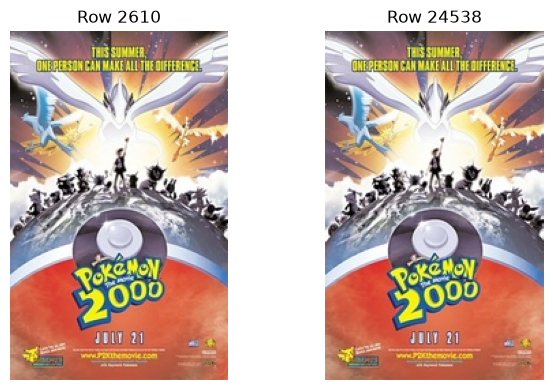

,Genres,Plot summary
Record ID,,
2610,"[Animation, Action, Adventure, Family, Fantasy]","An evil genius in a flying fortress is trying to kidnap the birds of the fire, ice, and lightning islands in hopes of luring the sea power, Lugia, and controlling the world. Ash and his friends, in the process of carrying out an island tradition that requires visiting those three islands, discover the plot and try to stop it. Even the comic villains, Team Rocket, turn good and help out in the end against the threat of world destruction. And Pokemon assemble from all around the world in case they can be of help (but they end up helping only the merchandising)."
24538,"[Animation, Action, Adventure, Family, Fantasy]","An evil genius in a flying fortress is trying to kidnap the birds of the fire, ice, and lightning islands in hopes of luring the sea power, Lugia, and controlling the world. Ash and his friends, in the process of carrying out an island tradition that requires visiting those three islands, discover the plot and try to stop it. Even the comic villains, Team Rocket, turn good and help out in the end against the threat of world destruction. And Pokemon assemble from all around the world in case they can be of help (but they end up helping only the merchandising)."


IDs 9103 and 14290 | Hamming distance 0 | Cosine 1.0000 | Shared genres 1 | Exact image: True | Exact text: True


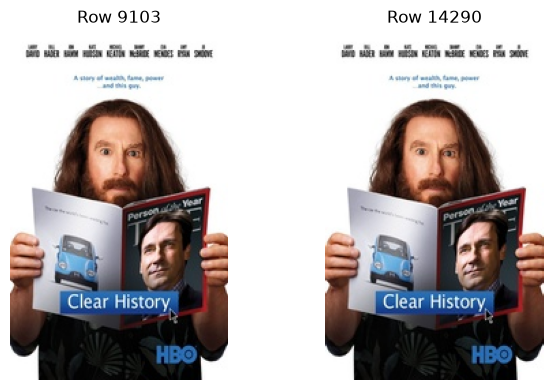

,Genres,Plot summary
Record ID,,
9103,[Comedy],"A PR specialist refuses to market a car called a ""Howard"" - a colossal error that loses him a billion dollars and makes him a national joke. He loses his hair, shaves his beard, takes a new name, and moves to Martha's Vineyard. Jump ten years: ""Rolly"" is a popular local whose sangfroid evaporates when the Howard's inventor moves to the island. Rolly, his old self unrecognizable, hatches a plan to rid the island of his nemesis; he also decides to woo the billionaire's wife. Fellatio, a former girlfriend, a woman who's lost weight, her boyfriend, the band Chicago, a menacing Chechen, a bus load of ill children, and a pair of ne'er-do-wells with experience with explosives figure in the story."
14290,[Comedy],"A PR specialist refuses to market a car called a ""Howard"" - a colossal error that loses him a billion dollars and makes him a national joke. He loses his hair, shaves his beard, takes a new name, and moves to Martha's Vineyard. Jump ten years: ""Rolly"" is a popular local whose sangfroid evaporates when the Howard's inventor moves to the island. Rolly, his old self unrecognizable, hatches a plan to rid the island of his nemesis; he also decides to woo the billionaire's wife. Fellatio, a former girlfriend, a woman who's lost weight, her boyfriend, the band Chicago, a menacing Chechen, a bus load of ill children, and a pair of ne'er-do-wells with experience with explosives figure in the story."


IDs 19999 and 20778 | Hamming distance 0 | Cosine 1.0000 | Shared genres 2 | Exact image: True | Exact text: True


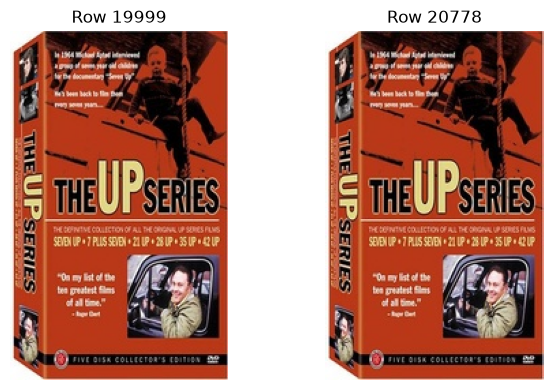

,Genres,Plot summary
Record ID,,
19999,"[Documentary, Biography]",Director
20778,"[Documentary, Biography]",Director


IDs 9538 and 25589 | Hamming distance 0 | Cosine 1.0000 | Shared genres 5 | Exact image: True | Exact text: True


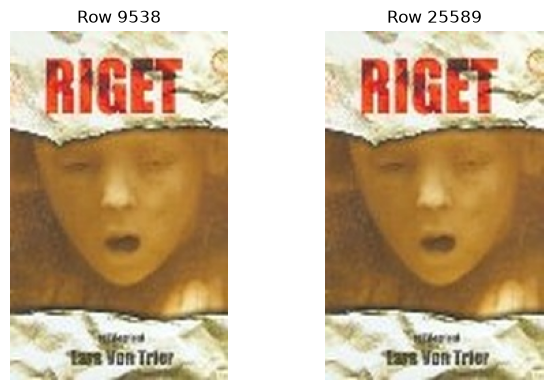

,Genres,Plot summary
Record ID,,
9538,"[Comedy, Drama, Fantasy, Horror, Mystery]","The Kingdom is the most technologically advanced hospital in Denmark, a gleaming bastion of medical science. A rash of uncanny occurrences, however, begins to weaken the staff's faith in science--a phantom ambulance pulls in every night, but disappears; voices echo in the elevator shaft; and a pregnant doctor's fetus seems to be developing much faster than is natural. At the goading of a spiritualist patient, some employees work to let supernatural forces rest."
25589,"[Comedy, Drama, Fantasy, Horror, Mystery]","The Kingdom is the most technologically advanced hospital in Denmark, a gleaming bastion of medical science. A rash of uncanny occurrences, however, begins to weaken the staff's faith in science--a phantom ambulance pulls in every night, but disappears; voices echo in the elevator shaft; and a pregnant doctor's fetus seems to be developing much faster than is natural. At the goading of a spiritualist patient, some employees work to let supernatural forces rest."


IDs 18745 and 23939 | Hamming distance 0 | Cosine 1.0000 | Shared genres 4 | Exact image: True | Exact text: True


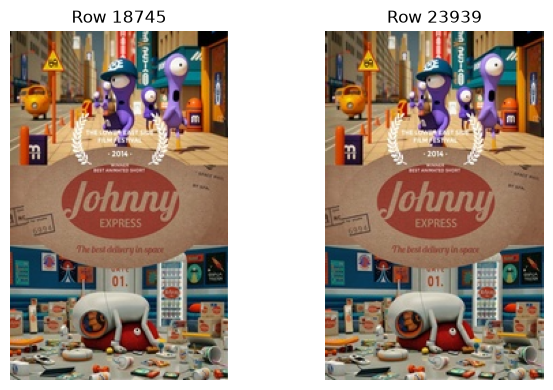

,Genres,Plot summary
Record ID,,
18745,"[Animation, Short, Comedy, Sci-Fi]","It's 2150. There are all sorts of Aliens living throughout space. Johnny is a Space Delivery Man who travels to different planets to deliver packages. Johnny is lazy and his only desire is to sleep in his autopilot spaceship. when the spaceship arrives at the destination, all he has to do is simply deliver the box. However, it never goes as planned. Johnny encounters strange and bizarre planets and always seems to cause trouble on his delivery route."
23939,"[Animation, Short, Comedy, Sci-Fi]","It's 2150. There are all sorts of Aliens living throughout space. Johnny is a Space Delivery Man who travels to different planets to deliver packages. Johnny is lazy and his only desire is to sleep in his autopilot spaceship. when the spaceship arrives at the destination, all he has to do is simply deliver the box. However, it never goes as planned. Johnny encounters strange and bizarre planets and always seems to cause trouble on his delivery route."


IDs 10875 and 13532 | Hamming distance 0 | Cosine 1.0000 | Shared genres 2 | Exact image: True | Exact text: True


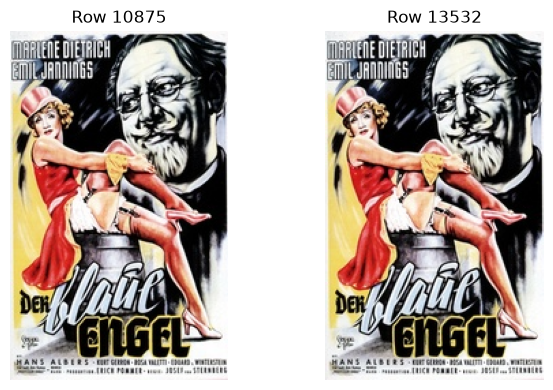

,Genres,Plot summary
Record ID,,
10875,"[Drama, Music]","Germany 1924. Middle aged Dr. Immanuel Rath is a literature professor at a boys college. Most of his students don't much like him, often calling him ""unrath"" - German for garbage. Dr. Rath learns that many of his boys often frequent a cabaret called Der blaue Engel - the Blue Angel - which he believes is corrupting their impressionable young minds. He heads to the Blue Angel himself to catch the boys in the act and shame them into not going again. Over several visits, Rath is able to catch the boys, but in the process he also understands what attracts the boys, namely the headlining performer Lola Lola. Rath falls under Lola's spell, he who falls in love with her - and she seemingly with him - so much so that he wants to marry her and give up his teaching career to be with her on her travels from cabaret to cabaret. Their relationship ends up not being what either envisioned, the question being how they will both deal with their disintegrating relationship and the reasons behind that disintegration."
13532,"[Drama, Music]","Germany 1924. Middle aged Dr. Immanuel Rath is a literature professor at a boys college. Most of his students don't much like him, often calling him ""unrath"" - German for garbage. Dr. Rath learns that many of his boys often frequent a cabaret called Der blaue Engel - the Blue Angel - which he believes is corrupting their impressionable young minds. He heads to the Blue Angel himself to catch the boys in the act and shame them into not going again. Over several visits, Rath is able to catch the boys, but in the process he also understands what attracts the boys, namely the headlining performer Lola Lola. Rath falls under Lola's spell, he who falls in love with her - and she seemingly with him - so much so that he wants to marry her and give up his teaching career to be with her on her travels from cabaret to cabaret. Their relationship ends up not being what either envisioned, the question being how they will both deal with their disintegrating relationship and the reasons behind that disintegration."


Near records
No pairs found.
Cutoff cases
Image cutoff, inside
IDs 11 and 229 | Hamming distance 6 | Cosine 0.0390 | Shared genres 1 | Exact image: False | Exact text: False


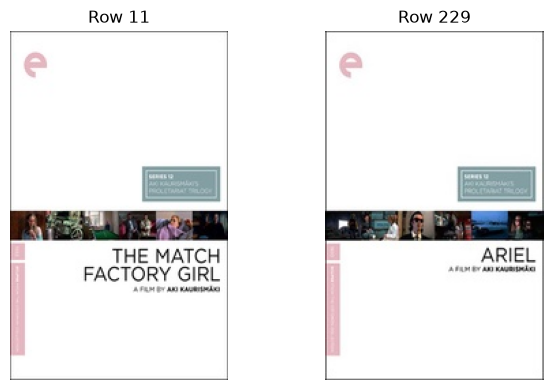

,Genres,Plot summary
Record ID,,
11,"[Drama, Comedy]","Iiris leads a bleak existence. She has a dead end job working on the assembly line at a match factory. What meager wages she earns all goes toward supporting her mother and stepfather, with who she lives in a small, crowded house. They largely ignore her unless she does something against their sensibilities, which leads to them exacting emotional and physical abuse toward her. And Iiris is also ignored socially, because of her overall somber demeanor and the fact that she has no money to make herself look more attractive to men. She believes her life will change with her chance meeting with well-off businessman, Aarne. However, what she believes is the start of a possible relationship with Aarne was solely a one-night stand for him, he who has no intention of ever seeing her again. The aftermath of this encounter with Aarne leads to Iiris making some decisions of how she will deal with her bleak life."
229,"[Comedy, Crime, Romance]","Taisto Kasurinen is a miner in a remote Finnish town. After the mine where he works shuts down permanently, he is given an unusual send-off by his father as he heads toward Helsinki to start a new life. That send off includes his father giving him his broken down, older model convertible whose top is now permanently in the down position. Taisto has little money in his pockets and needs to work odd jobs along the way to survive. On his way to Helsinki and once in Helsinki, Taisto gets into one misadventure after another. But the one bright spot for him in Helsinki is meeting single mother Irmeli Pihlaja, who works several jobs in order to pay for the modest items in her possession she has paid for in installments. They quickly fall for each other and plan to get married, that plan which hits a snag when an incident befalls Taisto. Although marrying Irmeli is foremost on his mind, he will have to decide how far he will go to achieve that end goal, and what that end goal will look like for him, Irmeli and her adolescent son."


Image cutoff, outside
IDs 1194 and 1276 | Hamming distance 8 | Cosine 0.0142 | Shared genres 1 | Exact image: False | Exact text: False


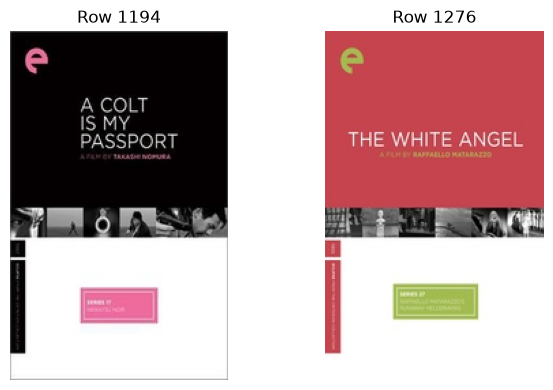

,Genres,Plot summary
Record ID,,
1194,"[Action, Crime, Drama]","The melancholy, homely Kamimura is a hit man who takes a job to kill a mob boss who's gotten greedy. The rival gang lord who hires Kamimura and his driver Shun pays them and sets them up in a hotel for a night while arranging safe passage on a ship. The son of the dead man comes to his rival and offers a partnership and cash in exchange for Kamimura's death. The boss considers his choice: morals or money? A maid at the hotel tries to aid the escape of Kamimura and Shun. As the two gangs close in, Kamimura chooses honor. Will his stoicism be his shroud?"
1276,[Drama],"Guido Carani, an engineer of noble descent, has just lost his son born to him by a chorus dancer, who, desperate, has become a nun. After a while he also loses his wife and daughter in a boating accident. Poor Guido is in despair, but soon he meets Lina, a woman who is a dead ringer for Luisa."


In [33]:
def show_duplicate_pair(pair):
    id1, id2, image_exact, text_exact, distance, cosine, shared = pair
    cosine_label = f"{cosine:.4f}" if np.isfinite(cosine) else "undefined"
    distance_label = "undefined" if pd.isna(distance) else str(distance)
    print(f"IDs {id1} and {id2} | Hamming distance {distance_label} | "
          f"Cosine {cosine_label} | Shared genres {shared} | "
          f"Exact image: {image_exact} | Exact text: {text_exact}")
    fig, axes = plt.subplots(1, 2, figsize=(7, 4))
    for axis, record_id in zip(axes, (id1, id2)):
        if has_image[record_id]:
            with decode_rgb(image_rows[record_id]["image"]) as poster:
                axis.imshow(poster)
        else:
            axis.text(0.5, 0.5, "Poster unavailable", ha="center", va="center", transform=axis.transAxes)
        axis.set_title(f"Row {record_id}")
        axis.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    details = data.loc[[id1, id2], ["labels", "text"]].rename(
        columns={"labels": "Genres", "text": "Plot summary"}
    ).rename_axis("Record ID")
    with pd.option_context("display.max_colwidth", None):
        display(details)


for label, frame in (("Exact records", exact_records), ("Near records", near_records)):
    print(label)
    if frame.empty:
        print("No pairs found.")
    for pair in frame.sample(n=len(frame), random_state=SEED).itertuples(index=False, name=None):
        show_duplicate_pair(pair)

print("Cutoff cases")
if not boundary_rows:
    print("No candidates within the review margins.")
for label, pair in boundary_rows.items():
    print(label)
    show_duplicate_pair(pair)

## Train, dev, and test split audit

`build_splits()` uses two rounds of iterative stratification to keep individual genre frequencies and genre pair frequencies proportionate. It sets aside about 30% for test, then takes `0.10 / 0.70` of the rest for dev, leaving about 60% for train. The helper reuses `data/mm-imdb/splits.npz` if it exists and creates it on the first run. The assertions check that the three arrays partition the original row positions.

In [34]:
from utils.mmimdb import SPLIT_FILE, build_splits

audit_labels = ds.select_columns(["labels"])
assert data.index.equals(pd.RangeIndex(len(audit_labels)))

audit_cached = SPLIT_FILE.exists()
audit_random_state = np.random.get_state()
try:
    np.random.seed(SEED)
    audit_splits = build_splits(audit_labels, GENRES)
finally:
    np.random.set_state(audit_random_state)

audit_names = ("train", "dev", "test")
audit_indices = [audit_splits[name] for name in audit_names]
assert all(idx.ndim == 1 and idx.size and np.issubdtype(idx.dtype, np.integer)
           for idx in audit_indices)
assert np.array_equal(np.sort(np.concatenate(audit_indices)), np.arange(len(audit_labels)))

audit_y = build_label_matrix(audit_labels, GENRES).astype(np.int64)
audit_sets = {"Full": audit_y, **{name: audit_y[idx] for name, idx in zip(audit_names, audit_indices)}}
audit_sizes = pd.Series({name: len(y) for name, y in audit_sets.items()}, name="movies")
audit_size_table = pd.DataFrame({
    "movies": audit_sizes,
    "share (%)": 100 * audit_sizes / len(audit_y),
    "target (%)": pd.Series({"Full": 100, "train": 60, "dev": 10, "test": 30}),
})
print(f"{'Reused' if audit_cached else 'Created'} split cache at {SPLIT_FILE}")
display(audit_size_table.round(2))

Created split cache at D:\VKhang\Study\HK261\DL\CO3133-DeepLearning\data\mm-imdb\splits.npz


,movies,share (%),target (%)
Full,25959,100.00,100
train,15544,59.88,60
dev,2594,9.99,10
test,7821,30.13,30


### Compare genre prevalence

Divide the number of movies with each genre by the size of its set. A movie can count toward several genres, so the genre rates within a set can sum to more than 100%. The difference from the full dataset is in percentage points.

In [35]:
audit_genre_counts = pd.DataFrame(
    {name: y.sum(axis=0) for name, y in audit_sets.items()}, index=GENRES
)
audit_genre_rates = audit_genre_counts.div(audit_sizes, axis="columns") * 100
audit_genre_delta = audit_genre_rates[list(audit_names)].sub(audit_genre_rates["Full"], axis=0)
audit_genre_table = pd.concat({
    "Count": audit_genre_counts,
    "Rate (%)": audit_genre_rates,
    "Change vs full (pp)": audit_genre_delta,
}, axis="columns")
display(audit_genre_table.sort_values(("Rate (%)", "Full"), ascending=False).round(3))

Count                   Rate (%)                          \
              Full train   dev  test     Full   train     dev    test   
Drama        13967  8380  1397  4190   53.804  53.911  53.855  53.574   
Comedy        8592  5155   859  2578   33.098  33.164  33.115  32.963   
Romance       5364  3202   546  1616   20.663  20.600  21.049  20.662   
Thriller      5192  3115   519  1558   20.001  20.040  20.008  19.921   
Crime         3838  2311   387  1140   14.785  14.867  14.919  14.576   
Action        3550  2124   361  1065   13.675  13.664  13.917  13.617   
Adventure     2710  1621   276   813   10.440  10.428  10.640  10.395   
Horror        2703  1622   270   811   10.413  10.435  10.409  10.370   
Documentary   2082  1249   208   625    8.020   8.035   8.019   7.991   
Mystery       2057  1234   206   617    7.924   7.939   7.941   7.889   
Sci-Fi        1991  1195   199   597    7.670   7.688   7.672   7.633   
Fantasy       1933  1157   193   583    7.446   7.443   7.440   7.454   
Family        1668   994   177   497    6.426   6.395   6.823   6.355   
Biography     1343   798   140   405    5.174   5.134   5.397   5.178   
War           1335   801   133   401    5.143   5.153   5.127   5.127   
History       1143   672   116   355    4.403   4.323   4.472   4.539   
Music         1045   630   104   311    4.026   4.053   4.009   3.976   
Animation      997   597   100   300    3.841   3.841   3.855   3.836   
Musical        841   496    91   254    3.240   3.191   3.508   3.248   
Western        705   423    70   212    2.716   2.721   2.699   2.711   
Sport          634   379    68   187    2.442   2.438   2.621   2.391   
Short          471   283    47   141    1.814   1.821   1.812   1.803   
Film-Noir      338   194    37   107    1.302   1.248   1.426   1.368   

            Change vs full (pp)                
                          train    dev   test  
Drama                     0.107  0.051 -0.230  
Comedy                    0.066  0.017 -0.136  
Romance                  -0.064  0.385 -0.001  
Thriller                  0.039  0.007 -0.080  
Crime                     0.083  0.134 -0.209  
Action                   -0.011  0.241 -0.058  
Adventure                -0.011  0.200 -0.044  
Horror                    0.022 -0.004 -0.043  
Documentary               0.015 -0.002 -0.029  
Mystery                   0.015  0.017 -0.035  
Sci-Fi                    0.018  0.002 -0.036  
Fantasy                  -0.003 -0.006  0.008  
Family                   -0.031  0.398 -0.071  
Biography                -0.040  0.224  0.005  
War                       0.010 -0.016 -0.016  
History                  -0.080  0.069  0.136  
Music                     0.027 -0.016 -0.049  
Animation                 0.000  0.014 -0.005  
Musical                  -0.049  0.268  0.008  
Western                   0.005 -0.017 -0.005  
Sport                    -0.004  0.179 -0.051  
Short                     0.006 -0.003 -0.012  
Film-Noir                -0.054  0.124  0.066

### Compare genre co-occurrence

For each set, `Y.T @ Y` counts the movies that carry both genres. Divide by the set size to compare rates across different sample sizes. The diagonal is the single-genre prevalence. The top row uses one shared color scale, and the bottom row shows each split minus the full dataset on a common scale centered at zero. The tables and plots describe the realized split, so rounded or rare combinations can differ from the target distribution.

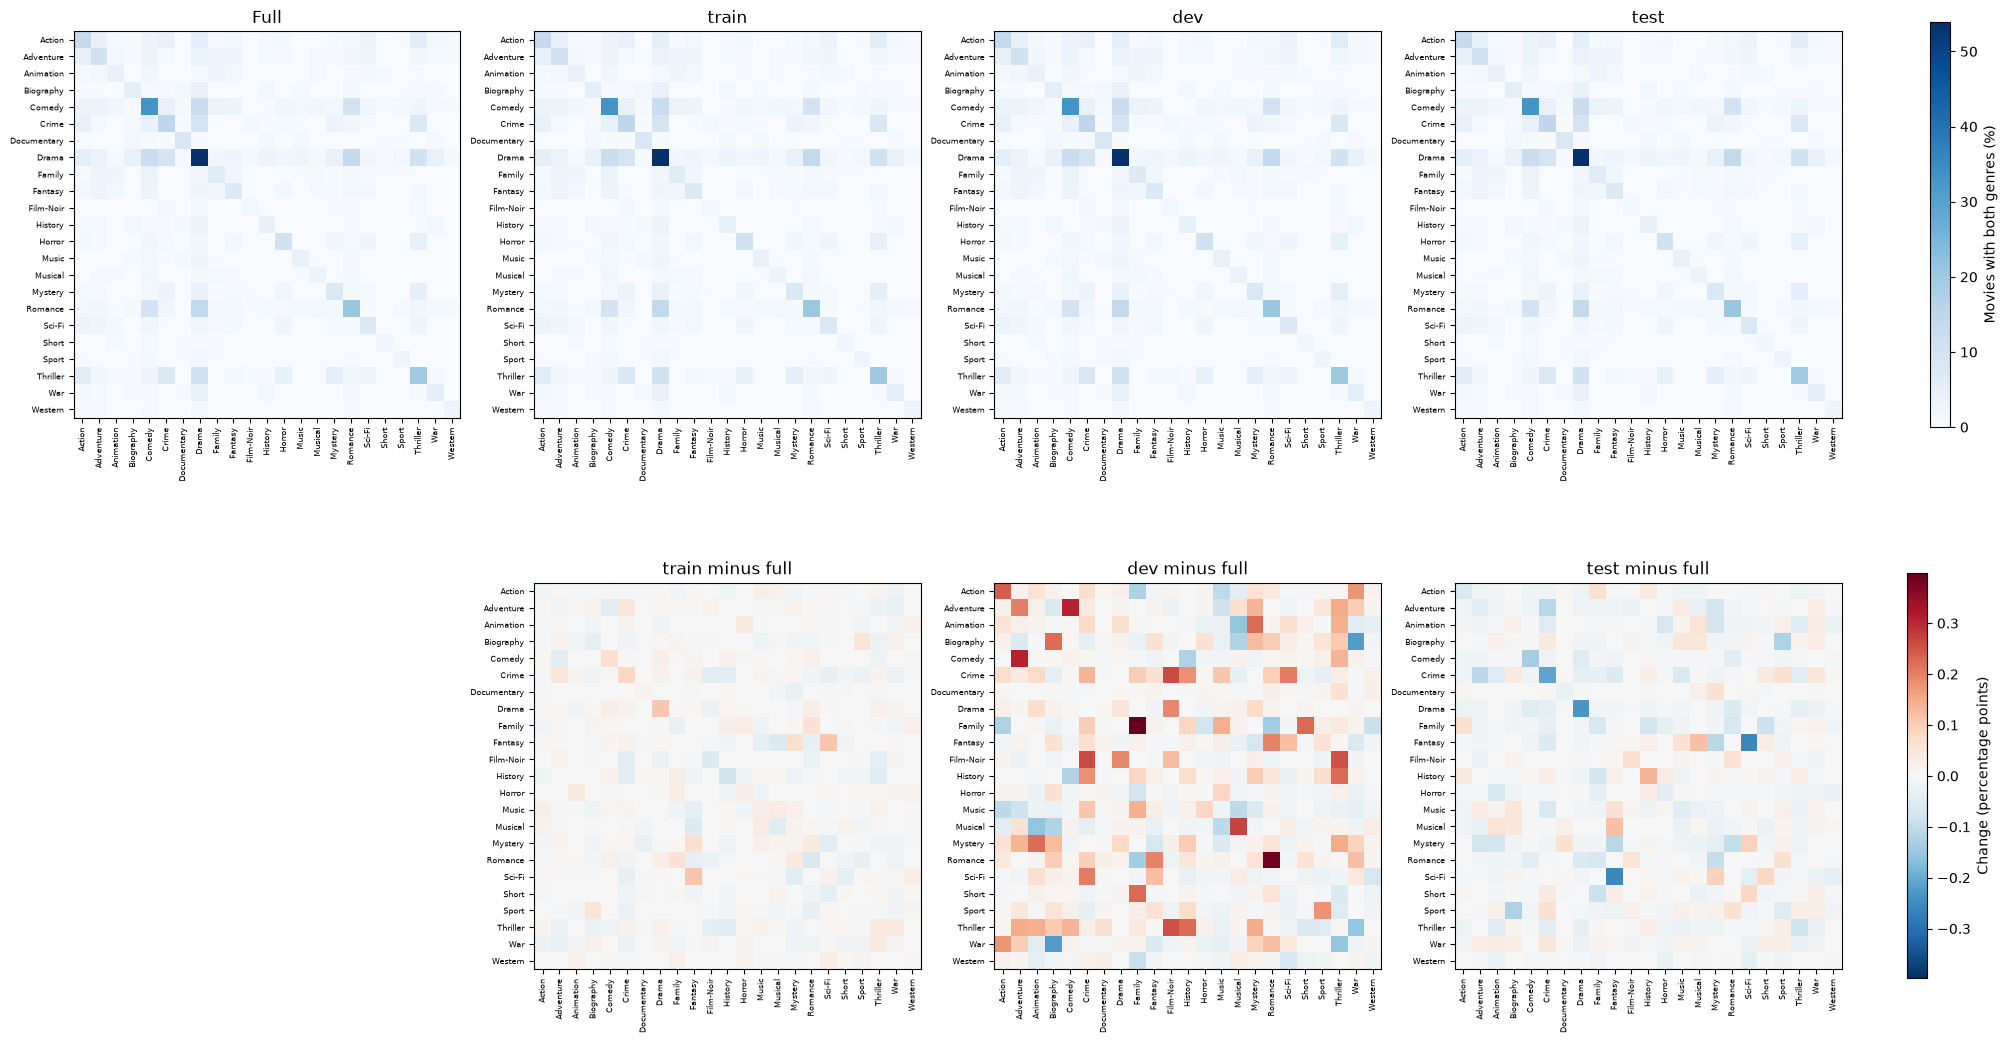

Largest changes among distinct genre pairs (split columns are in percentage points)


,,train,dev,test,Full rate (%)
Genre 1,Genre 2,,,,
Adventure,Comedy,-0.043,0.307,-0.017,3.047
Crime,Film-Noir,-0.044,0.263,0.001,0.932
Fantasy,Sci-Fi,0.109,0.120,-0.257,1.190
Film-Noir,Thriller,-0.040,0.255,-0.006,0.786
Family,Short,0.006,0.224,-0.086,0.393
History,Thriller,-0.052,0.224,0.029,0.354
Animation,Mystery,-0.001,0.224,-0.072,0.200
Biography,War,0.022,-0.223,0.031,0.570
Crime,Sci-Fi,-0.033,0.205,-0.003,0.374


In [36]:
audit_pair_counts = {
    name: pd.DataFrame(y.T @ y, index=GENRES, columns=GENRES)
    for name, y in audit_sets.items()
}
audit_pair_rates = {
    name: 100 * counts / audit_sizes[name] for name, counts in audit_pair_counts.items()
}
audit_pair_delta = {
    name: audit_pair_rates[name] - audit_pair_rates["Full"] for name in audit_names
}
assert all(np.array_equal(np.diag(counts), audit_genre_counts[name].to_numpy())
           for name, counts in audit_pair_counts.items())

audit_rate_max = max(matrix.to_numpy().max() for matrix in audit_pair_rates.values())
audit_delta_max = max(np.abs(matrix.to_numpy()).max() for matrix in audit_pair_delta.values())
audit_delta_max = audit_delta_max or 1.0


def plot_split_matrix(ax, matrix, title, cmap, vmin, vmax):
    heatmap = ax.imshow(matrix, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(title)
    ax.set_xticks(range(len(GENRES)), GENRES, rotation=90, fontsize=6)
    ax.set_yticks(range(len(GENRES)), GENRES, fontsize=6)
    return heatmap


fig, axes = plt.subplots(2, 4, figsize=(20, 11), layout="constrained")
for ax, (name, matrix) in zip(axes[0], audit_pair_rates.items()):
    rate_heatmap = plot_split_matrix(ax, matrix, name, "Blues", 0, audit_rate_max)
axes[1, 0].axis("off")
for ax, (name, matrix) in zip(axes[1, 1:], audit_pair_delta.items()):
    delta_heatmap = plot_split_matrix(
        ax, matrix, f"{name} minus full", "RdBu_r", -audit_delta_max, audit_delta_max
    )
fig.colorbar(rate_heatmap, ax=axes[0].tolist(), shrink=0.75, label="Movies with both genres (%)")
fig.colorbar(delta_heatmap, ax=axes[1, 1:].tolist(), shrink=0.75, label="Change (percentage points)")
plt.show()

# Rank distinct genre pairs by absolute change. Show each pair once.
audit_upper = np.triu_indices(len(GENRES), k=1)
audit_pair_names = pd.MultiIndex.from_arrays(
    [np.asarray(GENRES)[idx] for idx in audit_upper], names=["Genre 1", "Genre 2"]
)
audit_pair_changes = pd.DataFrame(
    {name: matrix.to_numpy()[audit_upper] for name, matrix in audit_pair_delta.items()},
    index=audit_pair_names,
)
audit_pair_changes["Full rate (%)"] = audit_pair_rates["Full"].to_numpy()[audit_upper]
audit_largest_changes = audit_pair_changes[list(audit_names)].abs().max(axis=1).nlargest(10).index
print("Largest changes among distinct genre pairs (split columns are in percentage points)")
display(audit_pair_changes.loc[audit_largest_changes].round(3))